# Croq'Pain

You can find the Croq'Pain case on pages 299-306 in the textbook, _Data, Models, and Decisions_. Please use the data set provided and not the data from the book.

`CroqPain.parquet` is the full data set that includes all stores as well as a set of 10 potential new store locations. Below, we provide some extra guidance as you work through each part of the case.

### Before you start ...

There is a problem in the data file `CroqPain.parquet` (i.e., the data needs some 'cleaning'). Find the issue and propose a fix before you continue with the analysis.

- Hint: Check data histograms

Post questions on Django as needed. Discuss your "fix" with the TAs during a work session or post your proposed data "fix" as a private post. Apply your fix and "store" it into a dataset called `CroqPainFix`.

### Part (a)

Visualize the data: examine histograms and scatterplots. Look at correlations between variables and try to identify sources of concern. Pay particular attention to the correlation for `total` and `P15` through `P55`. Do these correlations make sense to you?

Apply a transformation to the variables `EARN`, `P15`, `P25`, `P35`, `P45`, `P55`, `COMP`, `NCOMP`, and `NREST` where you normalize them by `total`. You can apply this normalization by defining new variables such as `EARN_total` which is equal to `EARN` divided by `total`.

Evaluate correlations and regressions with both the transformed and un-transformed data. Which do you prefer and why?

When you run regressions, be sure to use the `VIF` feature in Radiant for a more rigorous evaluation of multicollinearity. As you are building a model, it can also be useful to examine standardized coefficients. Also, conduct linear regression validation checks by using the `dashboard` plots in the `Plots` tab (see section 6.6 in the book).

If interested, you can experiment with the `Stepwise selection` option in the _Summary_ tab (i.e., click the checkbox) in Radiant (launched from RStudio). This is a feature in Radiant that uses a purely statistical approach to model building based on the Akaike Information Criterion (AIC). It will go through a series of steps and recommend a final model (see the bottom of the output). Compare the model selected using `Stepwise selection` to the model you arrived at yourself. Be critical and make a decision about the final model to recommend for Croq`Pain.

### Part (b)

Remember to use a subset of the `CroqPainFix` data with only the 50 stores opened up prior to 1994. After you build your regression model using `CroqPainFix` select the `Predict` tab in Radiant.

### Part (c)

This part can be completed using the same Radiant features applied earlier.

---

Copyright (c), 2018 by Vincent Nijs, Rady School of Management,
University of California, San Diego, Otterson Hall, 3W116,
9500 Gilman Drive, MC 0553, La Jolla, California 92093-0553,
e-mail: vnijs@ucsd.edu


### Data Cleaning


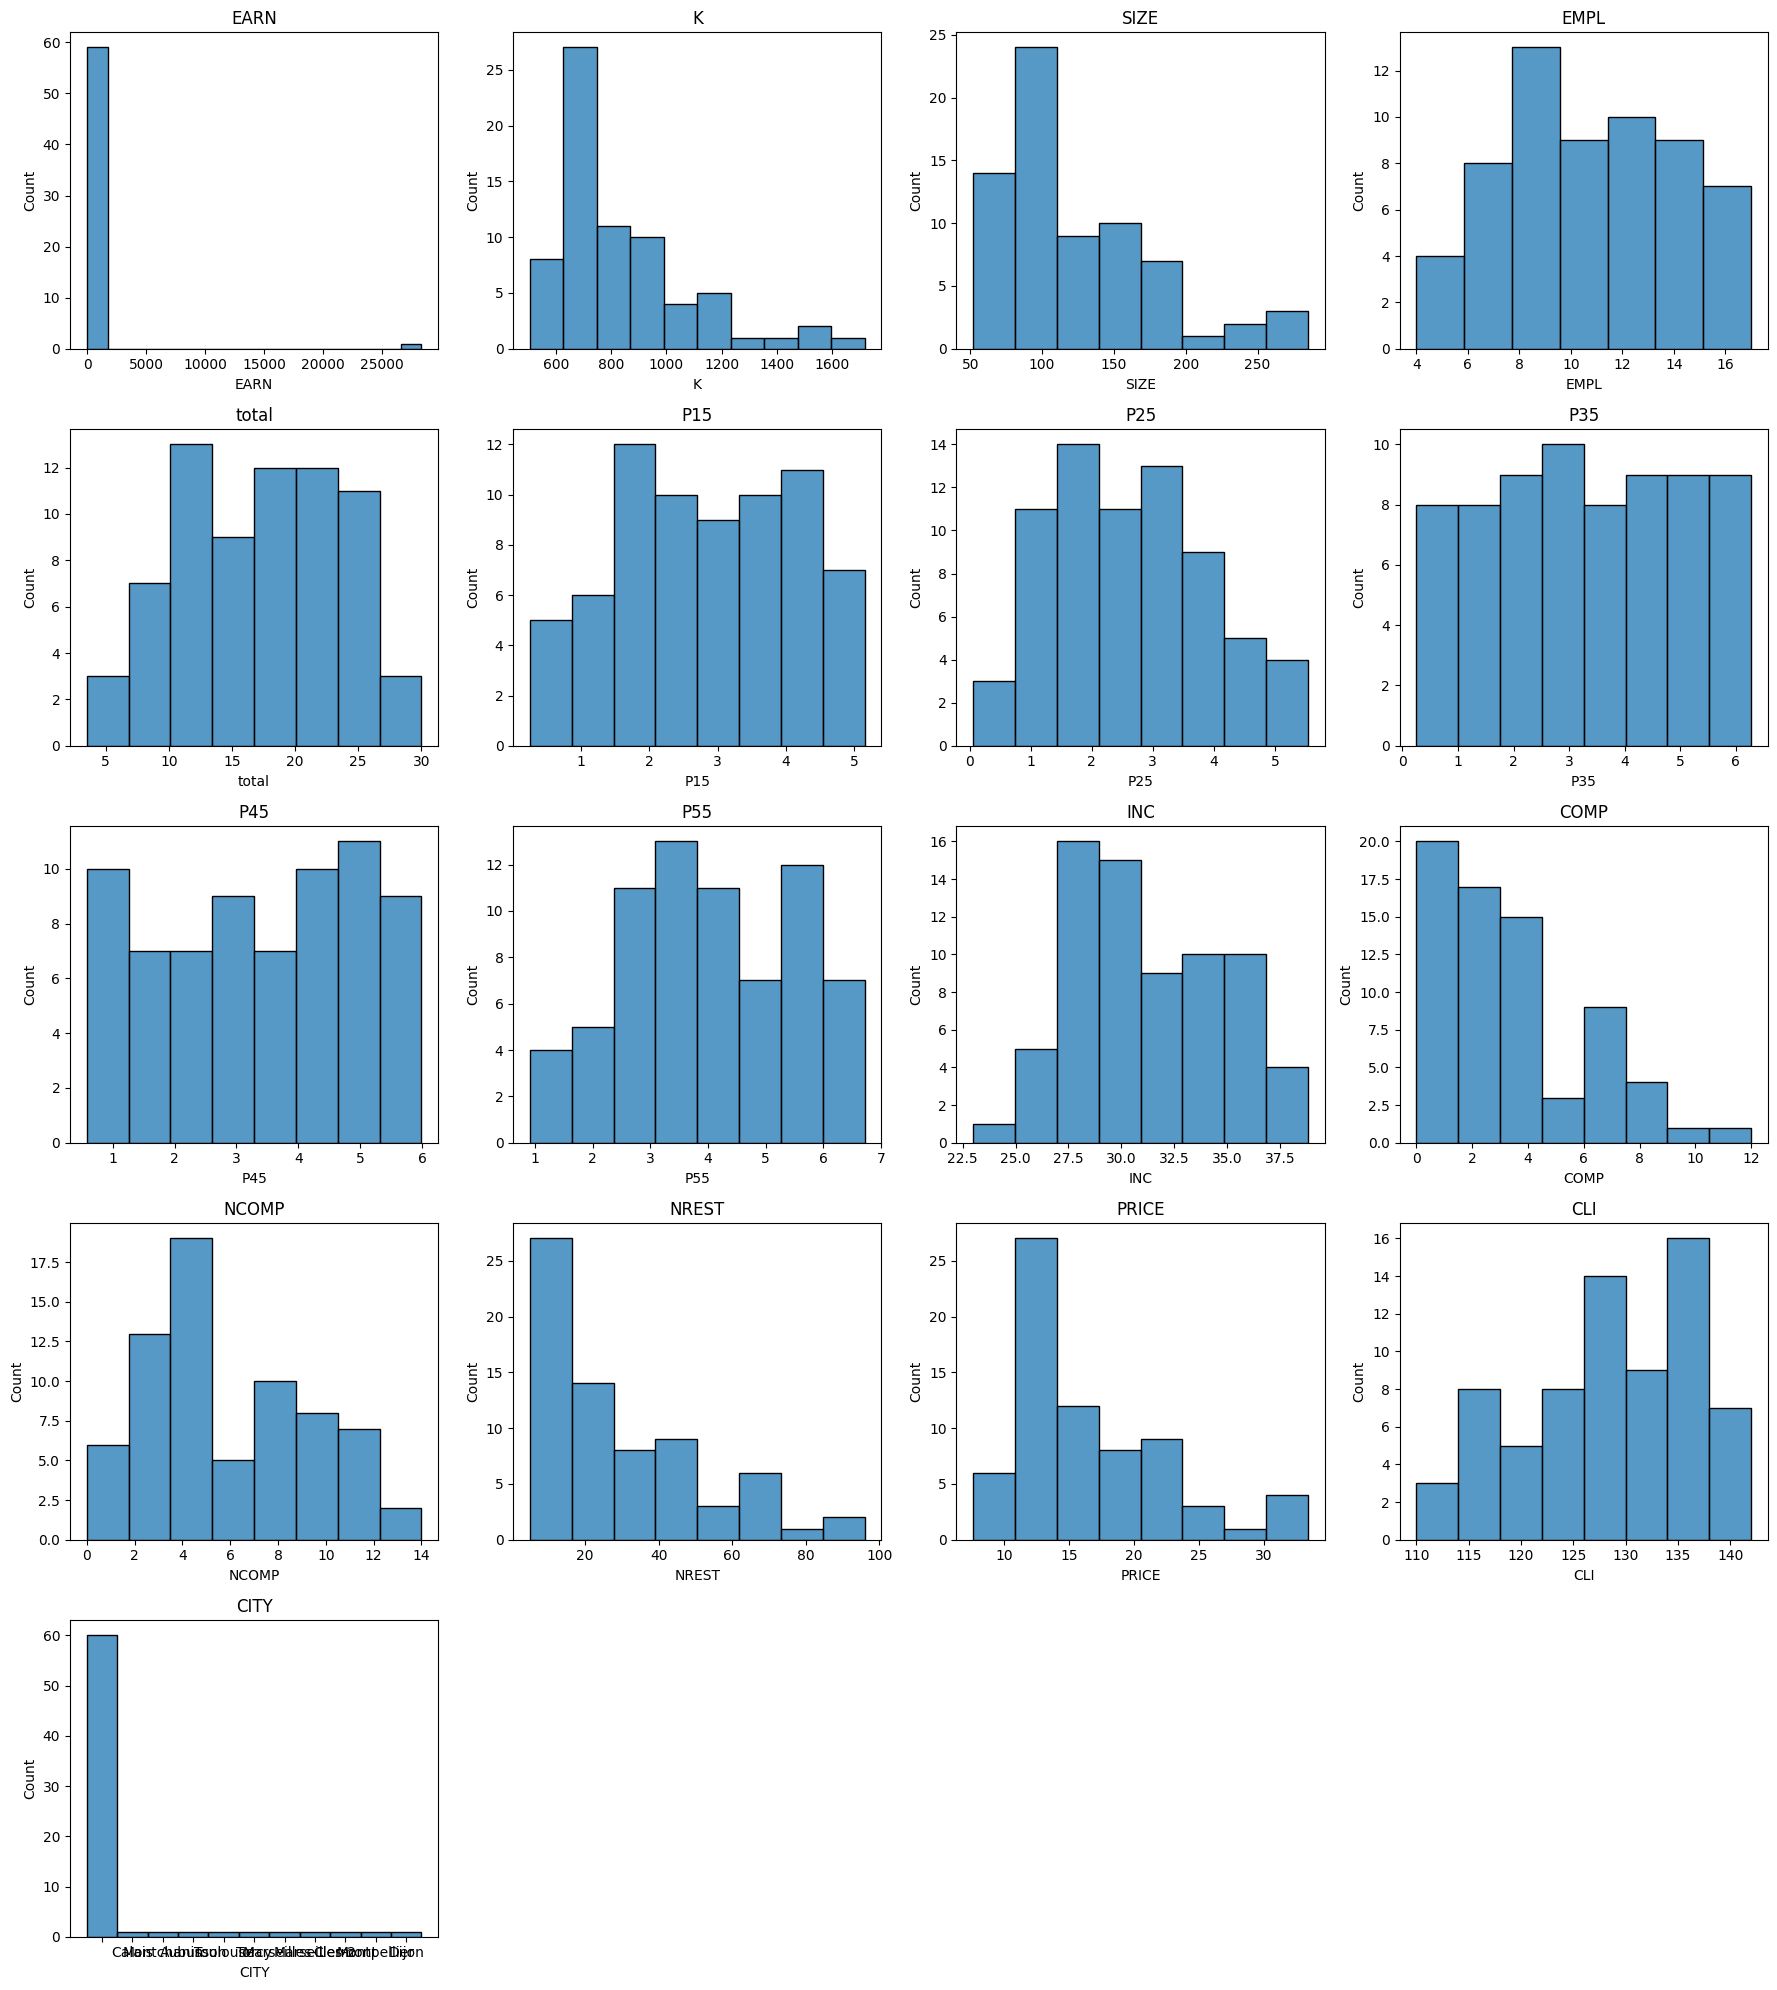

In [14]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

# load the data
crop = pl.read_parquet("CroqPain.parquet")
# histogram
plot_data = crop.drop("STOR")


def plot_histograms(data):
    plot_data = data.drop("STOR")
    columns = plot_data.columns

    ncols = 4
    nrows = math.ceil(len(columns) / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))

    axes = axes.flatten()

    for i, col in enumerate(columns):
        sns.histplot(data=plot_data, x=col, bins="auto", ax=axes[i])

        axes[i].set_title(col)

    for j in range(len(columns), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


plot_histograms(crop)

In [15]:
# check EARN
print(crop["EARN"].describe())
max_index = crop["EARN"].arg_max()
# correct the EARN
CroqPainFix = (
    crop.with_row_index("index")
    .with_columns(
        pl.when(pl.col("index") == max_index)
        .then(pl.col("EARN") / 1000)
        .otherwise(pl.col("EARN"))
        .alias("EARN")
    )
    .drop("index")
)

shape: (9, 2)
┌────────────┬─────────────┐
│ statistic  ┆ value       │
│ ---        ┆ ---         │
│ str        ┆ f64         │
╞════════════╪═════════════╡
│ count      ┆ 60.0        │
│ null_count ┆ 10.0        │
│ mean       ┆ 614.812261  │
│ std        ┆ 3641.044163 │
│ min        ┆ -42.97957   │
│ 25%        ┆ 77.555497   │
│ 50%        ┆ 140.907696  │
│ 75%        ┆ 214.177975  │
│ max        ┆ 28339.67262 │
└────────────┴─────────────┘


### Part A


#### Histogram


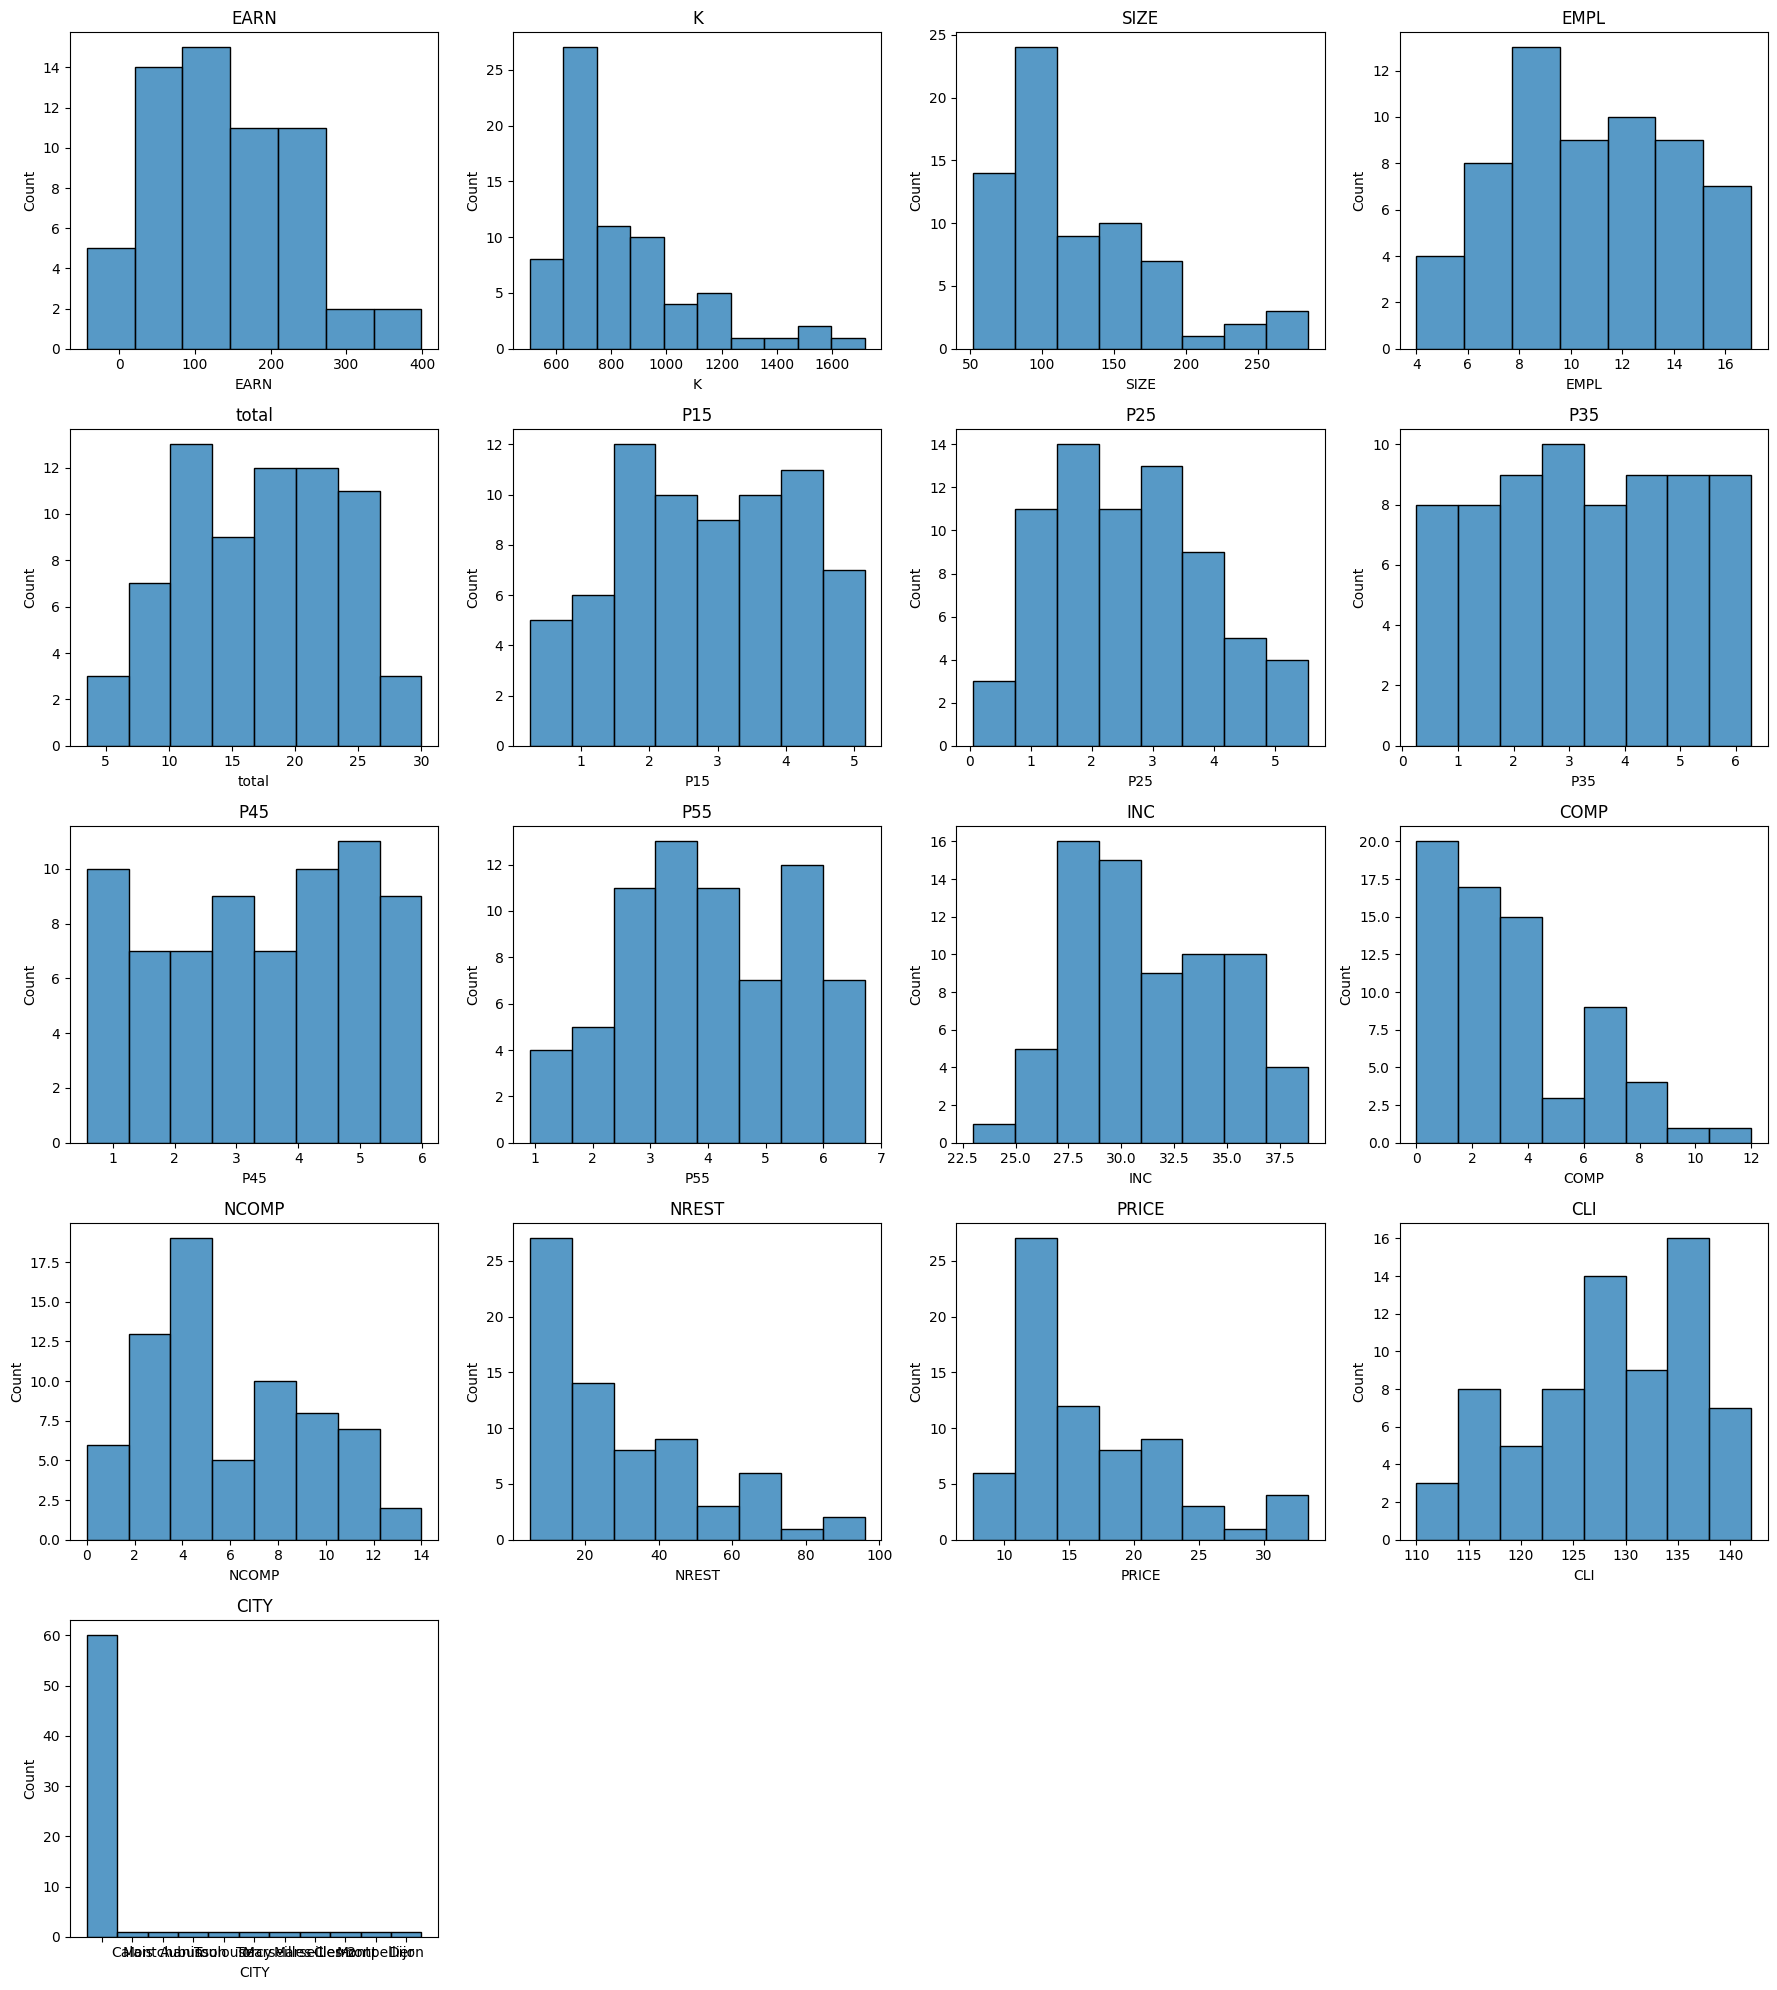

In [16]:
# histogram
plot_histograms(CroqPainFix)

#### Scatterplot


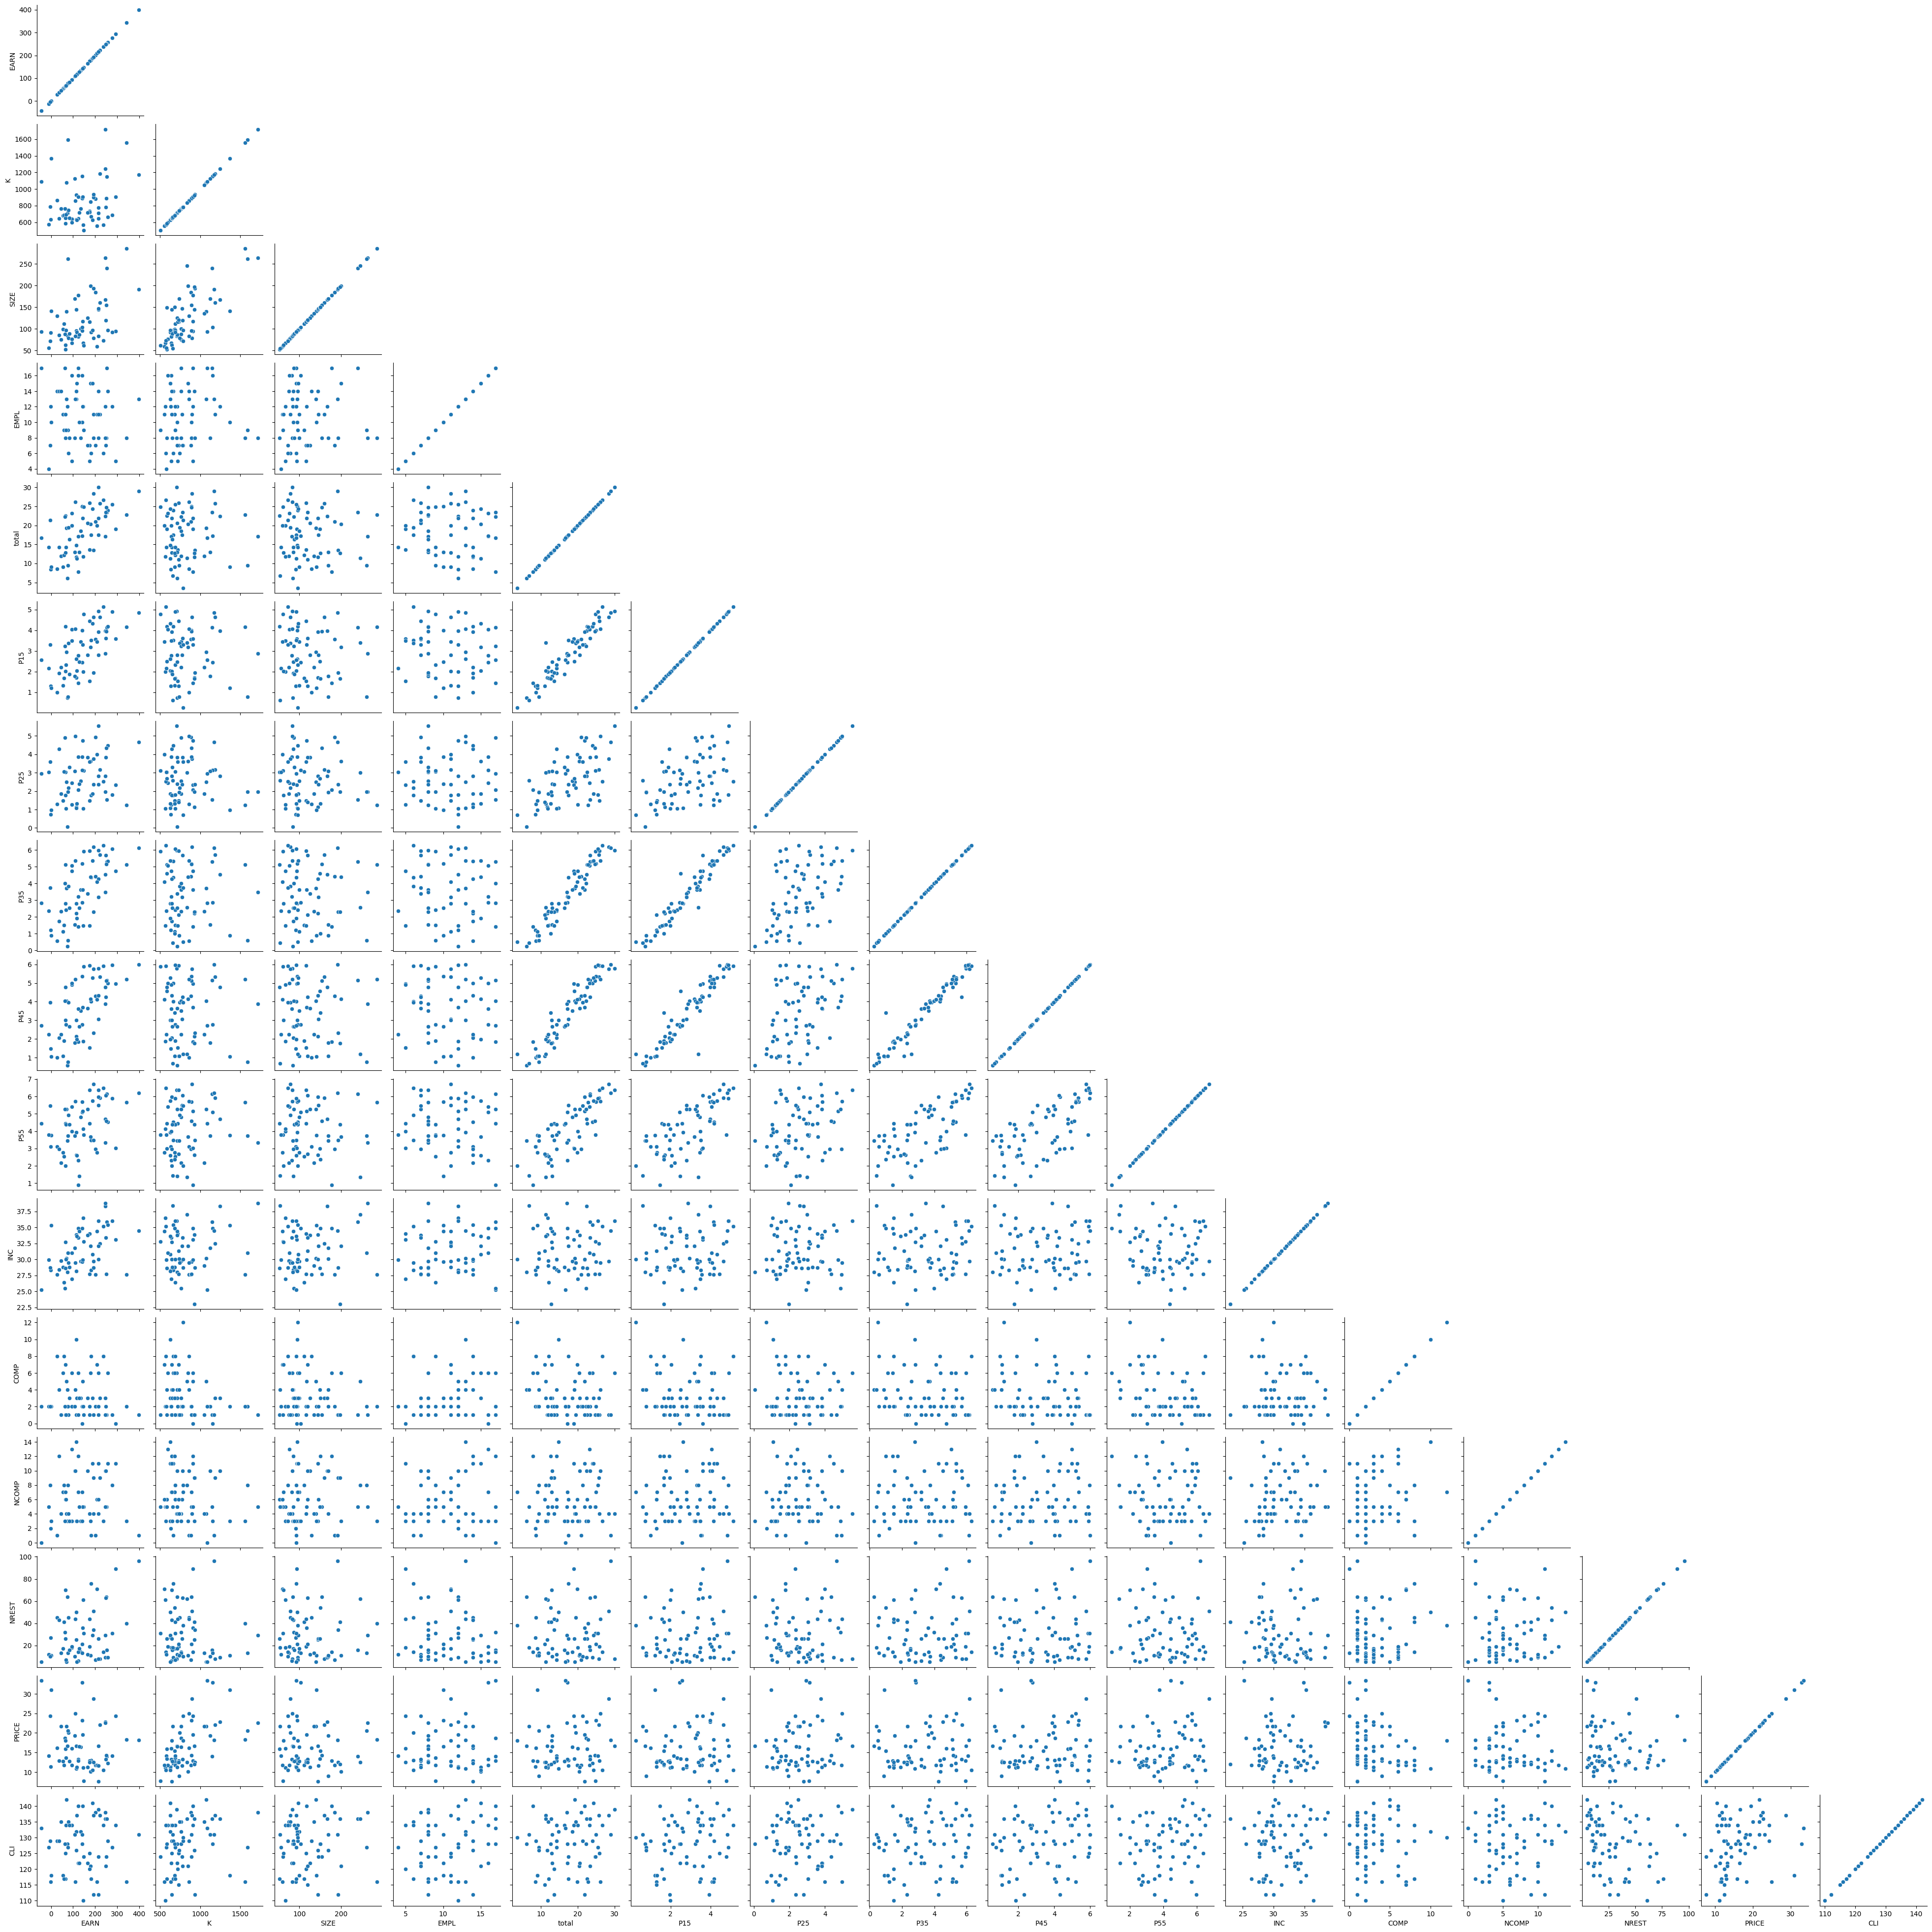

In [17]:
pairplot_data = CroqPainFix.drop("STOR", "CITY").to_pandas()

sns.pairplot(pairplot_data, corner=True, diag_kind=None)

plt.show()

#### Correlation Matrix


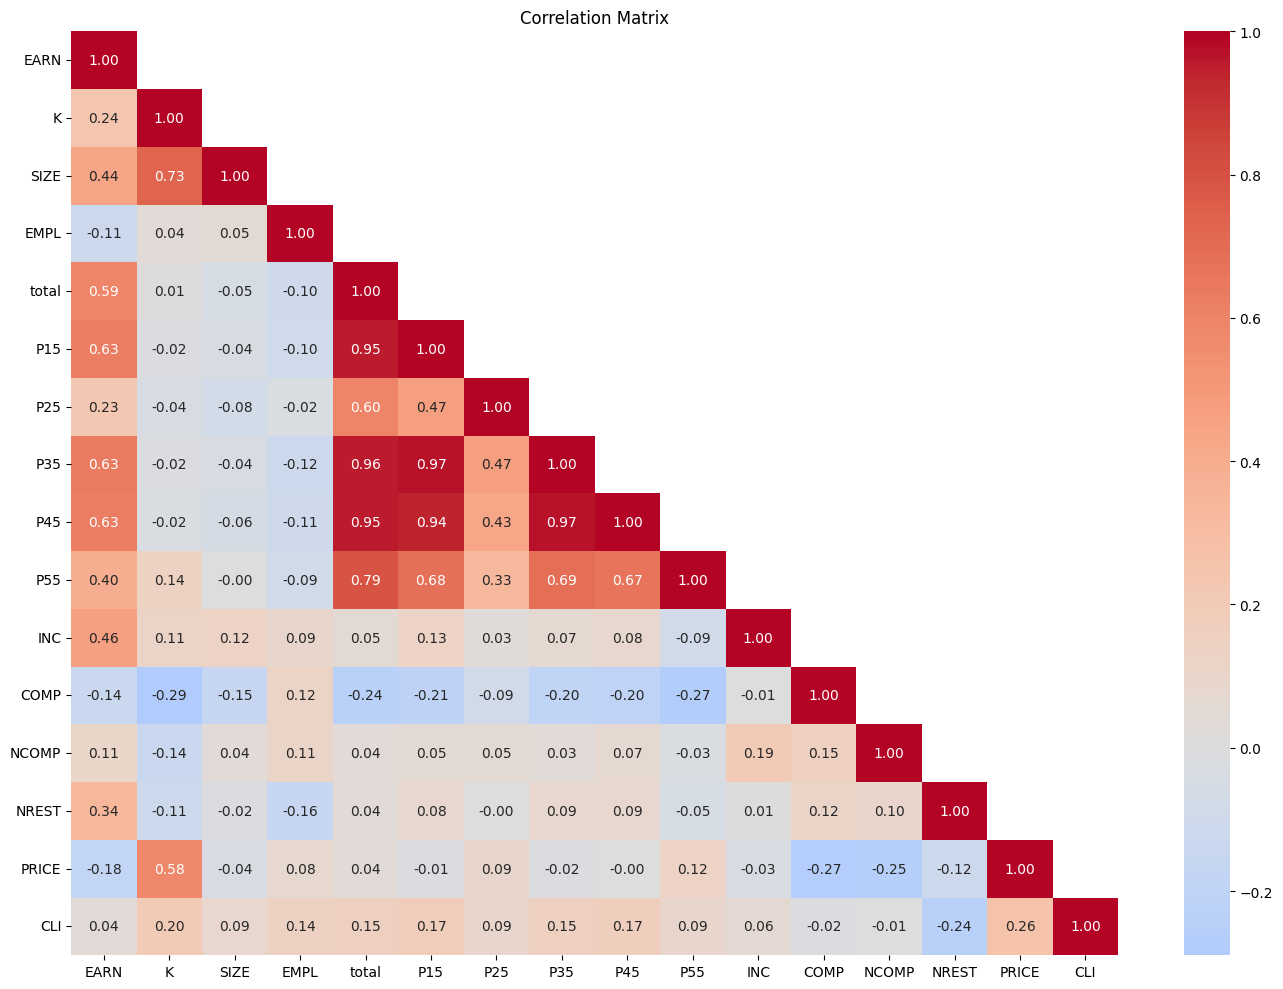

In [18]:
def plot_correlation(data, title):
    correlation_matrix = data.corr()
    plt.figure(figsize=(14, 10))
    sns.heatmap(
        correlation_matrix,
        mask=np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1),
        annot=True,
        cmap="coolwarm",
        center=0,
        fmt=".2f",
    )

    plt.title(title)
    plt.tight_layout()
    plt.show()


plot_correlation(pairplot_data, "Correlation Matrix")

As the correlation matrix shows, there is a strong positive relationship between total population(total) and the five age-group variables. Specifically, total is highly correlated with P15 (0.95), P35 (0.96), and P45 (0.95). However, its correlations with P25 (0.60) and P55 (0.79) are weaker. These correlations make sense because areas with larger populations are likely to have larger populations across different age groups. However, it also implies multicollinearity issues if total and all five age-group variables are included in the model. This is because they contain overlapping information. Additionally, it is notable that K is strongly positively related to size(0.73).


#### Variable Transformation


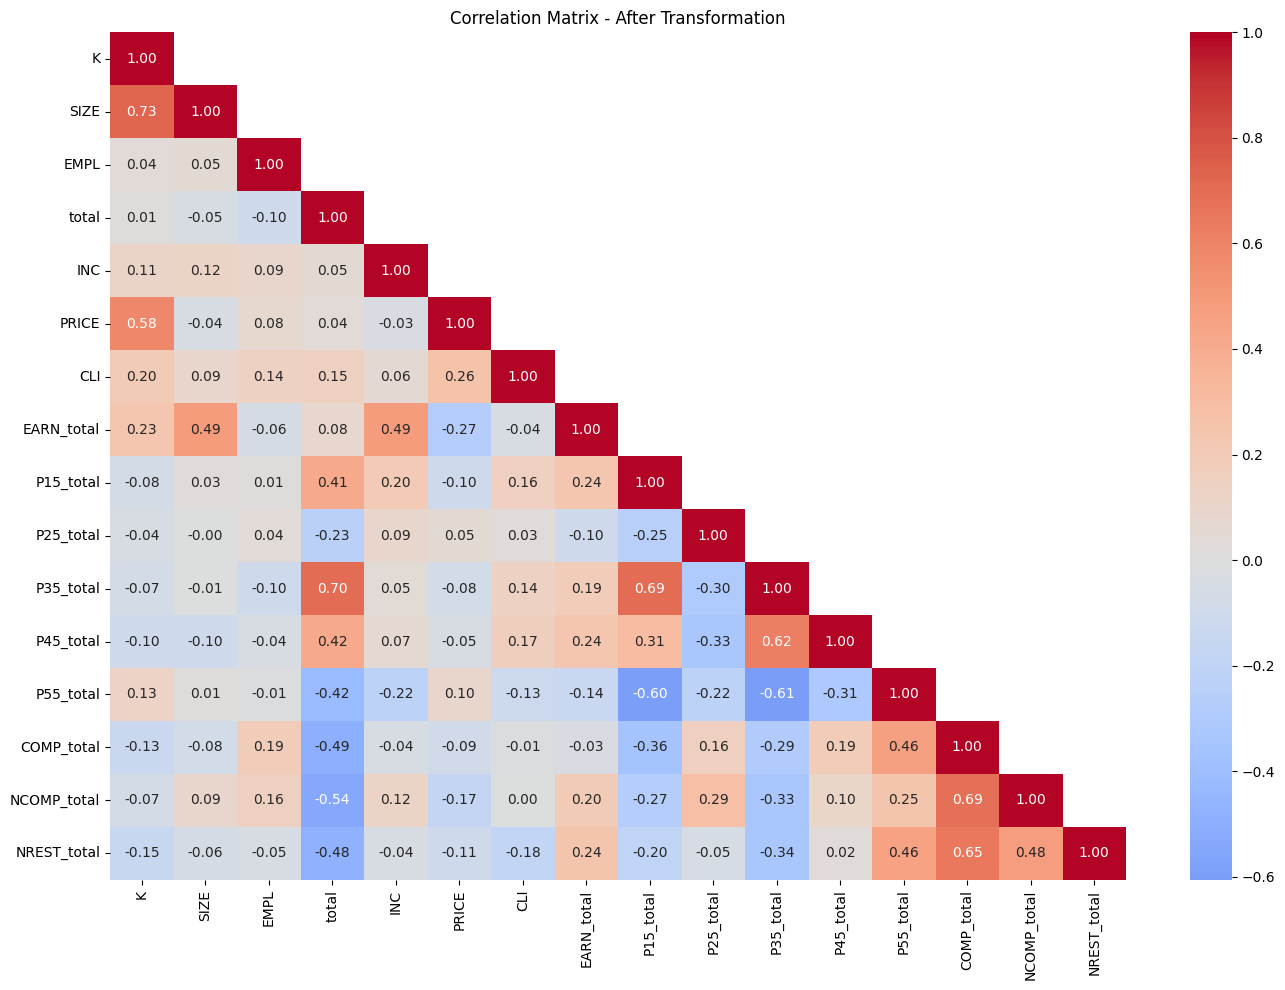

In [19]:
variables = ["EARN", "P15", "P25", "P35", "P45", "P55", "COMP", "NCOMP", "NREST"]

# normalize variables by total
CroqPainFix = CroqPainFix.with_columns(
    (pl.col(c) / pl.col("total")).alias(c + "_total") for c in variables
)

# transformed data
transformed_data = CroqPainFix.drop(["STOR", "CITY"] + variables).to_pandas()

# correlation matrix
plot_correlation(transformed_data, "Correlation Matrix - After Transformation")

After transformation, the correlations between total population (total) and the five age-group variables significantly decreased. However, the correlations among the five age-group variables themselves remain relatively strong. This suggests that the transformation does not completely solve the multicollinearity problem. In addition, COMP_total and NCOMP_total have a correlation of 0.69, while COMP_total and NREST_total have a correlation of 0.65.


#### Regression Analysis


In [20]:
import pyrsm as rsm

original_x = [
    "K",
    "SIZE",
    "EMPL",
    "total",
    "P15",
    "P25",
    "P35",
    "P45",
    "P55",
    "INC",
    "COMP",
    "NCOMP",
    "NREST",
    "PRICE",
    "CLI",
]
reg_original = rsm.model.regress(CroqPainFix, rvar="EARN", evar=original_x)

reg_original.summary()

Linear regression (OLS)
Data                 : Not provided
Response variable    : EARN
Explanatory variables: K, SIZE, EMPL, total, P15, P25, P35, P45, P55, INC, COMP, NCOMP, NREST, PRICE, CLI
Null hyp.: the effect of x on EARN is zero
Alt. hyp.: the effect of x on EARN is not zero

┌───────────┬─────────────┬───────────┬─────────┬─────────┬─────┐
│ index     ┆ coefficient ┆ std.error ┆ t.value ┆ p.value ┆     │
╞═══════════╪═════════════╪═══════════╪═════════╪═════════╪═════╡
│ Intercept ┆ -405.514    ┆ 99.92     ┆ -4.058  ┆ < .001  ┆ *** │
│ K         ┆ -0.177      ┆ 0.109     ┆ -1.619  ┆ 0.113   ┆     │
│ SIZE      ┆ 1.442       ┆ 0.425     ┆ 3.389   ┆ 0.001   ┆ **  │
│ EMPL      ┆ -1.678      ┆ 1.525     ┆ -1.1    ┆ 0.277   ┆     │
│ total     ┆ -5.206      ┆ 12.848    ┆ -0.405  ┆ 0.687   ┆     │
│ P15       ┆ 58.444      ┆ 27.3      ┆ 2.141   ┆ 0.038   ┆ *   │
│ P25       ┆ 6.613       ┆ 13.764    ┆ 0.48    ┆ 0.633   ┆     │
│ P35       ┆ 5.802       ┆ 22.293    ┆ 0.26    ┆ 0.796

In [21]:
transformed_x = [
    "K",
    "SIZE",
    "EMPL",
    "total",
    "P15_total",
    "P25_total",
    "P35_total",
    "P45_total",
    "P55_total",
    "INC",
    "COMP_total",
    "NCOMP_total",
    "NREST_total",
    "PRICE",
    "CLI",
]

reg_transformed = rsm.model.regress(CroqPainFix, rvar="EARN_total", evar=transformed_x)

reg_transformed.summary()

Linear regression (OLS)
Data                 : Not provided
Response variable    : EARN_total
Explanatory variables: K, SIZE, EMPL, total, P15_total, P25_total, P35_total, P45_total, P55_total, INC, COMP_total, NCOMP_total, NREST_total, PRICE, CLI
Null hyp.: the effect of x on EARN_total is zero
Alt. hyp.: the effect of x on EARN_total is not zero

┌─────────────┬─────────────┬───────────┬─────────┬─────────┬─────┐
│ index       ┆ coefficient ┆ std.error ┆ t.value ┆ p.value ┆     │
╞═════════════╪═════════════╪═══════════╪═════════╪═════════╪═════╡
│ Intercept   ┆ -24.871     ┆ 11.624    ┆ -2.14   ┆ 0.038   ┆ *   │
│ K           ┆ -0.013      ┆ 0.007     ┆ -1.862  ┆ 0.069   ┆ .   │
│ SIZE        ┆ 0.092       ┆ 0.027     ┆ 3.453   ┆ 0.001   ┆ **  │
│ EMPL        ┆ -0.128      ┆ 0.098     ┆ -1.299  ┆ 0.201   ┆     │
│ total       ┆ 0.076       ┆ 0.095     ┆ 0.796   ┆ 0.43    ┆     │
│ P15_total   ┆ 58.605      ┆ 28.324    ┆ 2.069   ┆ 0.044   ┆ *   │
│ P25_total   ┆ 2.021       ┆ 12.816 

In [22]:
# VIF
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# original model
original_data = CroqPainFix.select(["EARN"] + original_x).to_pandas().dropna()

X_original = np.column_stack(
    (np.ones(len(original_data)), original_data[original_x].to_numpy())
)

vif_original = pd.DataFrame(
    {
        "Variable": original_x,
        "VIF": [
            variance_inflation_factor(X_original, i + 1) for i in range(len(original_x))
        ],
    }
)
# transformed model
transformed_x = [
    "K",
    "SIZE",
    "EMPL",
    "total",
    "P15_total",
    "P25_total",
    "P35_total",
    "P45_total",
    "P55_total",
    "INC",
    "COMP_total",
    "NCOMP_total",
    "NREST_total",
    "PRICE",
    "CLI",
]

transformed_vif_data = (
    CroqPainFix.select(["EARN_total"] + transformed_x).to_pandas().dropna()
)

X_transformed = np.column_stack(
    (np.ones(len(transformed_vif_data)), transformed_vif_data[transformed_x].to_numpy())
)

vif_transformed = pd.DataFrame(
    {
        "Variable": transformed_x,
        "VIF": [
            variance_inflation_factor(X_transformed, i + 1)
            for i in range(len(transformed_x))
        ],
    }
)

print(vif_original.round(4))

print(vif_transformed.round(4))

   Variable       VIF
0         K   35.6143
1      SIZE   22.1266
2      EMPL    1.2448
3     total  255.6396
4       P15   44.3498
5       P25   12.7393
6       P35   61.1405
7       P45  108.3672
8       P55   16.4066
9       INC    1.3721
10     COMP    1.2910
11    NCOMP    1.1768
12    NREST    1.2522
13    PRICE   12.6562
14      CLI    1.3713
       Variable      VIF
0             K  35.6427
1          SIZE  21.7468
2          EMPL   1.2882
3         total   3.4831
4     P15_total   4.6239
5     P25_total   6.3222
6     P35_total  15.4940
7     P45_total  14.1017
8     P55_total  11.3238
9           INC   1.3950
10   COMP_total   2.2392
11  NCOMP_total   1.7874
12  NREST_total   1.9732
13        PRICE  12.1411
14          CLI   1.3842


Both the original and transformed models are statistically significant, with p-values below 0.001. However, the original model performs better because its R-squared(0.875) is higher than that of the transformed model(0.769). Both models identify SIZE, P15 (P15_total), INC, and NREST (NREST_total) as statistically significant at the 5% level. Most other explanatory variables remain insignificant after transformation.

The VIF test results show that the original model has serious multicollinearity. 9 variables have VIF values above 10. In particular, total and P45 have extremely high VIF values. After transformation, the multicollinearity problem is reduced. However, some variables, including K, SIZE, P35_total, P45_total, P55_total, and PRICE, still have VIF values above 10.

Based on the current information, the full original model may be a better choice because it achieves a higher R-squared.


#### Optimal Model Building


In [23]:
# Stepwise AIC for original model
original_x = [
    "K",
    "SIZE",
    "EMPL",
    "total",
    "P15",
    "P25",
    "P35",
    "P45",
    "P55",
    "INC",
    "COMP",
    "NCOMP",
    "NREST",
    "PRICE",
    "CLI",
]

reg_original_step = rsm.model.regress(
    CroqPainFix, rvar="EARN", evar=original_x, stepwise=True
)

reg_original_step.summary()
# Stepwise AIC for transformed full model
transformed_x = [
    "K",
    "SIZE",
    "EMPL",
    "total",
    "P15_total",
    "P25_total",
    "P35_total",
    "P45_total",
    "P55_total",
    "INC",
    "COMP_total",
    "NCOMP_total",
    "NREST_total",
    "PRICE",
    "CLI",
]
reg_transformed_step = rsm.model.regress(
    CroqPainFix, rvar="EARN_total", evar=transformed_x, stepwise=True
)
reg_transformed_step.summary()

Start:  AIC=448.17
EARN ~ K + SIZE + EMPL + total + P15 + P25 + P35 + P45 + P55 + 
    INC + COMP + NCOMP + NREST + PRICE + CLI

        Df Sum of Sq    RSS    AIC
- NCOMP  1        18  61750 446.19
- P45    1        36  61768 446.21
- P35    1        95  61827 446.27
- P55    1       187  61919 446.35
- total  1       230  61962 446.40
- PRICE  1       277  62009 446.44
- P25    1       324  62056 446.49
- CLI    1       578  62310 446.73
- COMP   1      1318  63050 447.44
- EMPL   1      1699  63431 447.80
<none>                61732 448.17
- K      1      3679  65411 449.65
- P15    1      6430  68162 452.12
- SIZE   1     16116  77848 460.09
- INC    1     44569 106301 478.78
- NREST  1     52480 114212 483.09

Step:  AIC=446.19
EARN ~ K + SIZE + EMPL + total + P15 + P25 + P35 + P45 + P55 + 
    INC + COMP + NREST + PRICE + CLI

        Df Sum of Sq    RSS    AIC
- P45    1        50  61800 444.24
- P35    1        97  61847 444.28
- P55    1       173  61923 444.36
- total  1     

In [24]:
select_x = ["K", "SIZE", "P15", "INC", "NREST"]
reg_best_std = rsm.model.regress(
    CroqPainFix, rvar="EARN", evar=select_x, standardize=True
)
reg_best_std.summary()

Linear regression (OLS)
Data                 : Not provided
Response variable    : EARN
Explanatory variables: K, SIZE, P15, INC, NREST
Null hyp.: the effect of x on EARN is zero
Alt. hyp.: the effect of x on EARN is not zero
**Standardized coefficients shown (2 X SD)**

┌───────────┬─────────────┬───────────┬─────────┬─────────┬─────┐
│ index     ┆ coefficient ┆ std.error ┆ t.value ┆ p.value ┆     │
╞═══════════╪═════════════╪═══════════╪═════════╪═════════╪═════╡
│ Intercept ┆ -0.0        ┆ 0.025     ┆ -0.0    ┆ 1.0     ┆     │
│ K         ┆ -0.337      ┆ 0.087     ┆ -3.871  ┆ < .001  ┆ *** │
│ SIZE      ┆ 0.714       ┆ 0.086     ┆ 8.256   ┆ < .001  ┆ *** │
│ P15       ┆ 0.567       ┆ 0.051     ┆ 11.062  ┆ < .001  ┆ *** │
│ INC       ┆ 0.339       ┆ 0.052     ┆ 6.499   ┆ < .001  ┆ *** │
│ NREST     ┆ 0.353       ┆ 0.051     ┆ 6.96    ┆ < .001  ┆ *** │
└───────────┴─────────────┴───────────┴─────────┴─────────┴─────┘

Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

R-s

I applied backward stepwise selection separately to the original full model and the transformed full model. I chose the model from the original full model because it has fewer independent variables, and its R-squared is slightly lower than that of the full original model (0.864 vs. 0.875). This suggests that this model is still providing strong explanatory power.


#### OLS Assumptions Validation


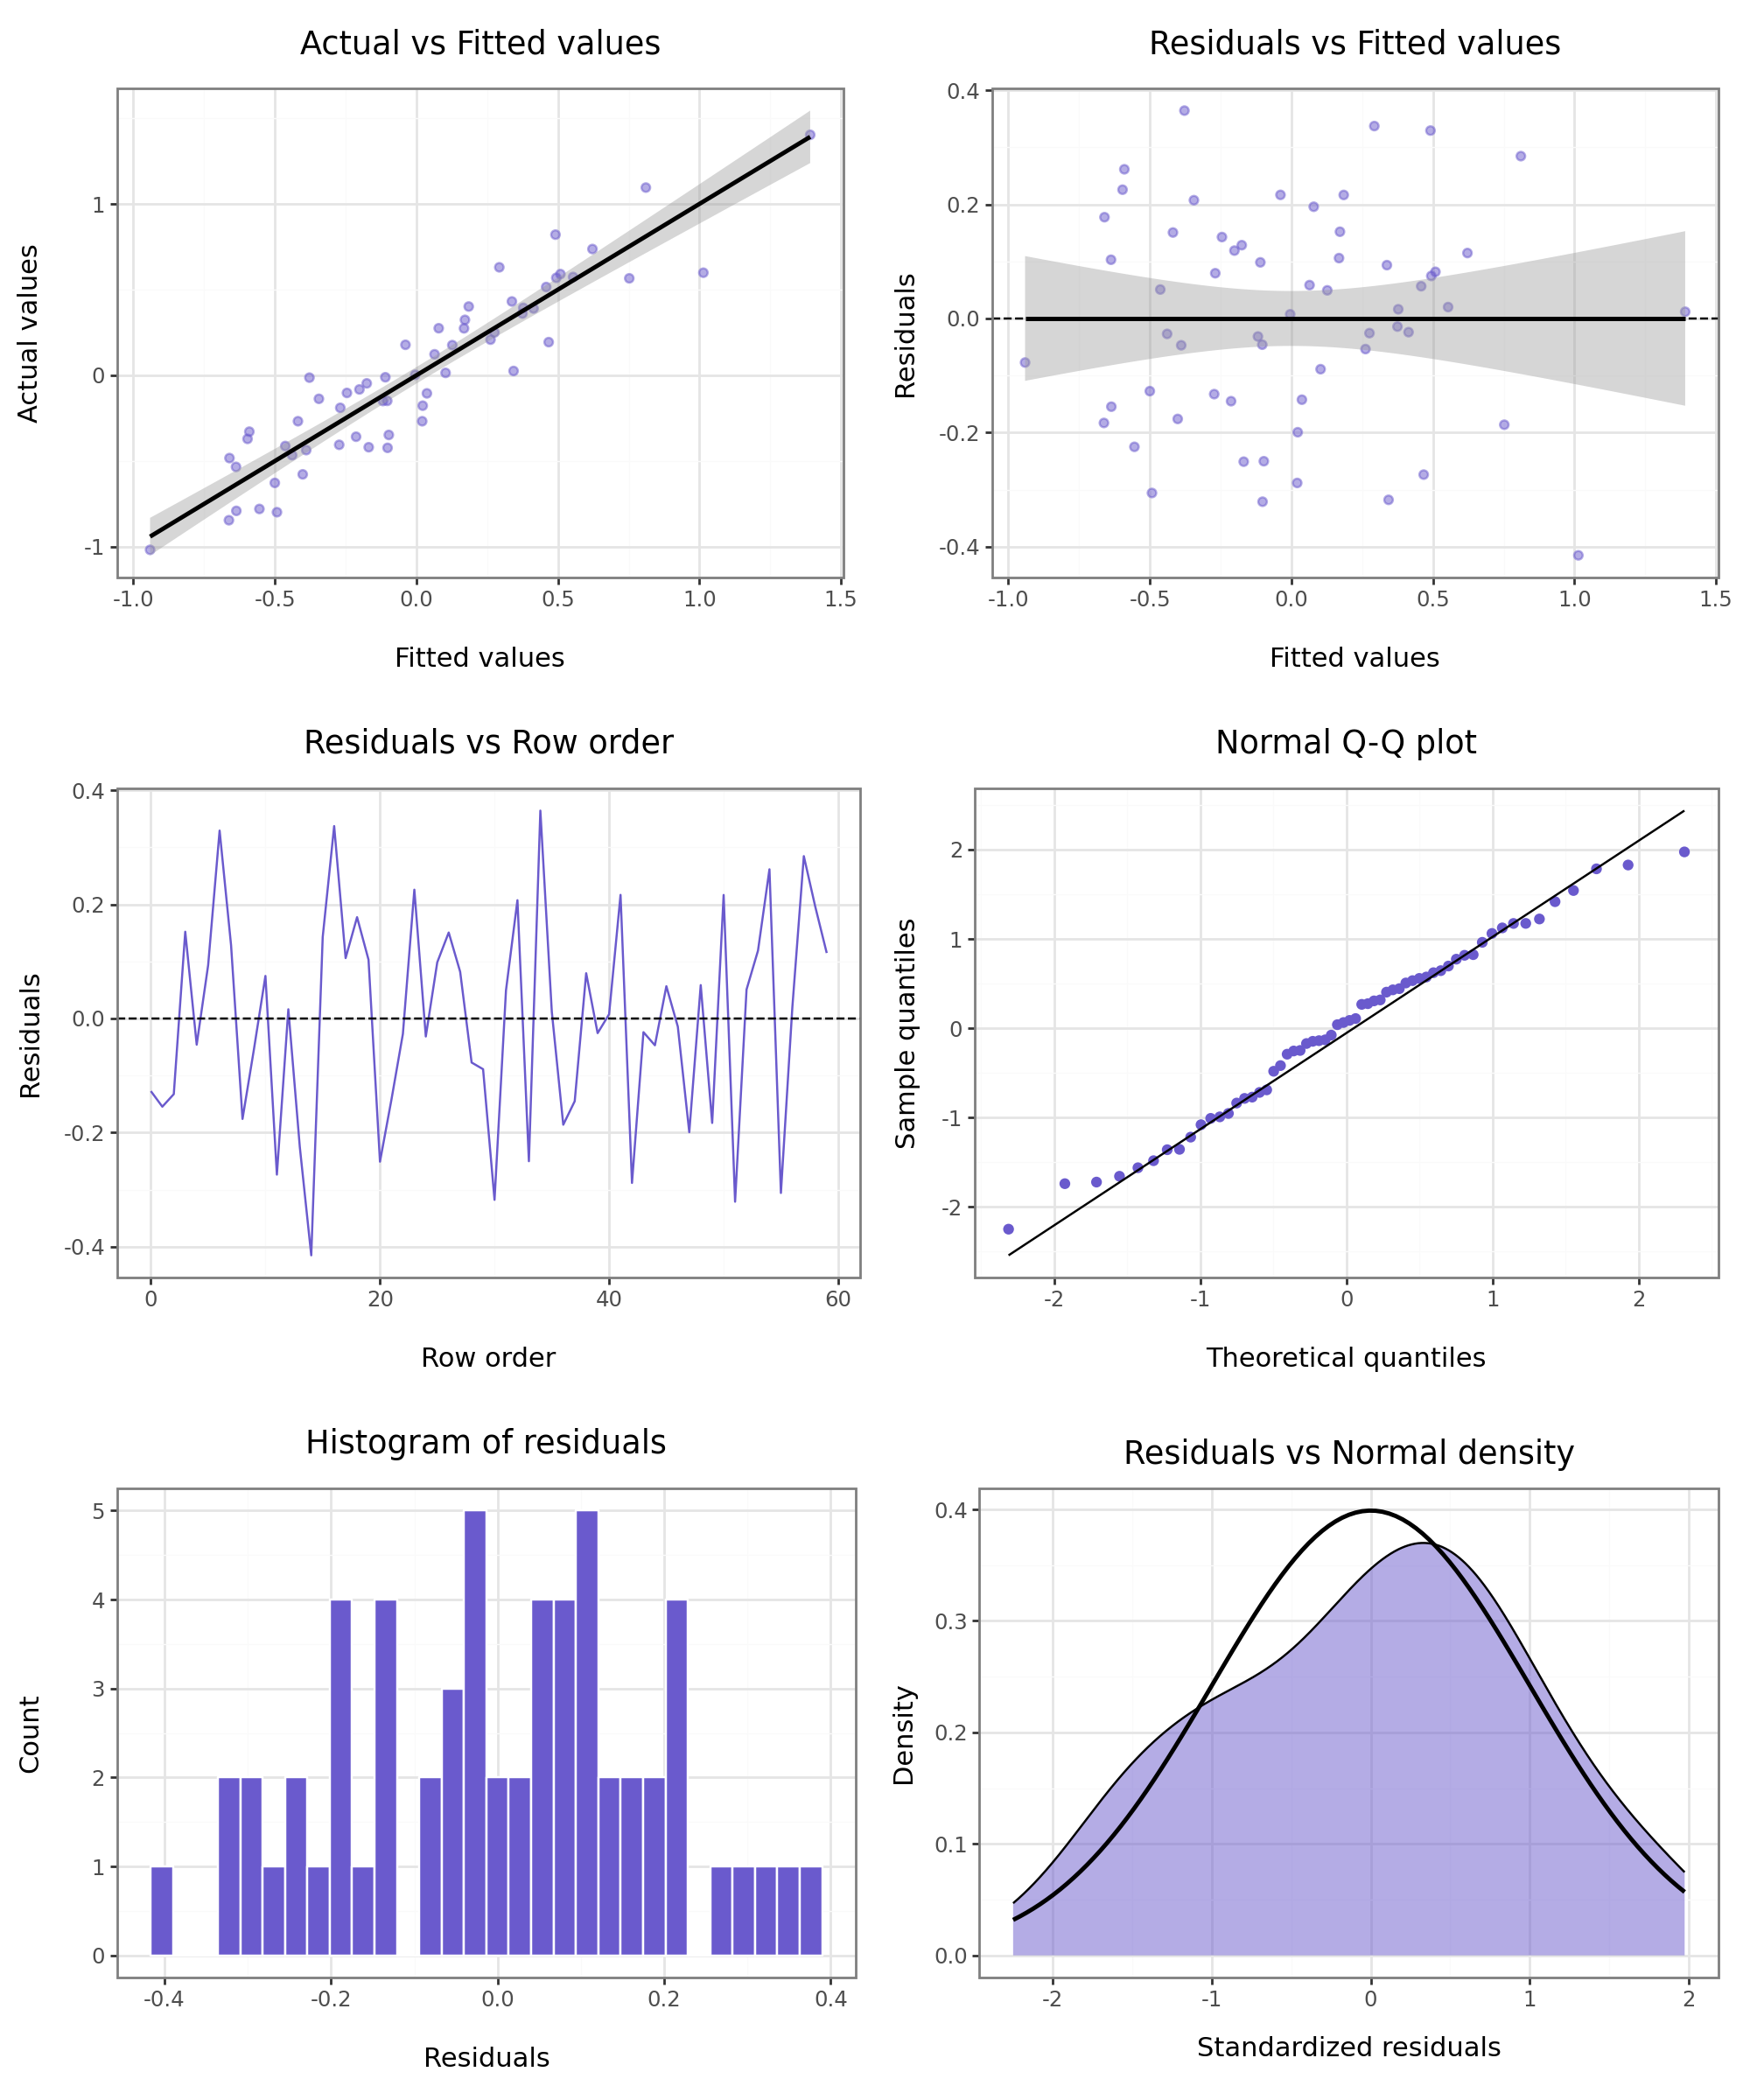

In [25]:
reg_best_std.plot("dashboard")

The diagnostic plots showed no clear problems with linearity, homoscedasticity, or independence. The residuals were approximately normally distributed.


#### VIF test


In [26]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = CroqPainFix.select(["EARN"] + select_x).drop_nulls().select(select_x).to_numpy()
X = np.column_stack((np.ones(X.shape[0]), X))
vif_final = pd.DataFrame(
    {
        "Variable": select_x,
        "VIF": [variance_inflation_factor(X, i + 1) for i in range(len(select_x))],
    }
)

print(vif_final.round(4))

  Variable     VIF
0        K  3.0128
1     SIZE  2.9648
2      P15  1.0405
3      INC  1.0808
4    NREST  1.0176


The VIF test indicates that there is no serious multicollinearity because all VIF values are below 5.


### Optimal Model Summary


The optimal model includes five independent variables: **K, SIZE, P15, INC, and NREST**.

The optimal model does not violate any of the basic assumptions of multiple regression and has no serious multicollinearity. It has a R-squared of 0.864 and an adjusted R-squared of 0.851. The overall model is statistically significant(p < 0.001), and all five independent variables are statistically significant(p < 0.001).


### Part B


In [27]:
croqpain_raw = pl.read_parquet("CroqPain.parquet")
print("Largest EARN before fix:", croqpain_raw["EARN"].max())

Largest EARN before fix: 28339.67262


In [28]:
croqpain_fixed = croqpain_raw.with_columns(
    pl.when(pl.col("STOR") == 1)
    .then(pl.col("EARN") / 1000)
    .otherwise(pl.col("EARN"))
    .alias("EARN")
)
print("Largest EARN after fix:", croqpain_fixed["EARN"].max())
print("Store 1 EARN after fix:", croqpain_fixed.filter(pl.col("STOR") == 1)["EARN"][0])

Largest EARN after fix: 399.2359194
Store 1 EARN after fix: 28.33967262


In [29]:
stores_before_1994 = croqpain_fixed.filter(pl.col("STOR") <= 50)
stores_opened_in_1994 = croqpain_fixed.filter(
    (pl.col("STOR") >= 51) & (pl.col("STOR") <= 60)
)
print("Number of stores before 1994:", stores_before_1994.height)
print("Number of stores opened in 1994:", stores_opened_in_1994.height)

Number of stores before 1994: 50
Number of stores opened in 1994: 10


In [30]:
import statsmodels.formula.api as smf

stores_before_1994_pandas = stores_before_1994.to_pandas()
earnings_model_50_stores = smf.ols(
    "EARN ~ K + SIZE + P15 + INC + NREST", data=stores_before_1994_pandas
).fit()
print(earnings_model_50_stores.summary())

                            OLS Regression Results                            
Dep. Variable:                   EARN   R-squared:                       0.872
Model:                            OLS   Adj. R-squared:                  0.857
Method:                 Least Squares   F-statistic:                     59.89
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.61e-18
Time:                        01:10:22   Log-Likelihood:                -242.82
No. Observations:                  50   AIC:                             497.6
Df Residuals:                      44   BIC:                             509.1
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -392.5661     46.153     -8.506      0.0

In [31]:
stores_opened_in_1994_pandas = stores_opened_in_1994.to_pandas()
stores_opened_in_1994_pandas["predicted_earnings"] = earnings_model_50_stores.predict(
    stores_opened_in_1994_pandas
)
stores_opened_in_1994_pandas["predicted_ratio"] = (
    stores_opened_in_1994_pandas["predicted_earnings"]
    / stores_opened_in_1994_pandas["K"]
)
stores_opened_in_1994_pandas["would_open"] = (
    stores_opened_in_1994_pandas["predicted_ratio"] >= 0.26
)
print(
    stores_opened_in_1994_pandas[
        ["STOR", "K", "predicted_earnings", "predicted_ratio", "would_open"]
    ].round(3)
)

   STOR         K  predicted_earnings  predicted_ratio  would_open
0    51   775.979             167.567            0.216       False
1    52   647.752             134.602            0.208       False
2    53   689.843              56.529            0.082       False
3    54   715.018             111.433            0.156       False
4    55   650.061              34.083            0.052       False
5    56   788.411              56.179            0.071       False
6    57   781.951             242.752            0.310        True
7    58  1557.841             260.894            0.167       False
8    59   935.575             138.946            0.149       False
9    60   687.978             259.147            0.377        True


In [32]:
stores_opened_in_1994_pandas["actual_ratio"] = (
    stores_opened_in_1994_pandas["EARN"] / stores_opened_in_1994_pandas["K"]
)
stores_opened_in_1994_pandas["actually_met_target"] = (
    stores_opened_in_1994_pandas["actual_ratio"] >= 0.26
)
print(
    stores_opened_in_1994_pandas[
        ["STOR", "predicted_ratio", "actual_ratio", "would_open", "actually_met_target"]
    ].round(3)
)

   STOR  predicted_ratio  actual_ratio  would_open  actually_met_target
0    51            0.216         0.279       False                 True
1    52            0.208         0.101       False                False
2    53            0.082         0.098       False                False
3    54            0.156         0.179       False                False
4    55            0.052         0.128       False                False
5    56            0.071        -0.004       False                False
6    57            0.310         0.317        True                 True
7    58            0.167         0.220       False                False
8    59            0.149         0.206       False                False
9    60            0.377         0.403        True                 True


We built the model on the first 50 stores using K, SIZE, P15, INC and NREST (R-squared = 0.872) and used it to predict the 10 stores opened in 1994. Only stores 57 and 60 reached the 0.26 target, so these are the two we would have opened. Compared with the actual results, the model got 9 out of 10 stores right. The one miss was store 51: we predicted 0.216, but it actually reached 0.279. With only 10 stores to check, we can't say much about how accurate the model is overall, but it worked well here.


### Part C


In [33]:
stores_existing = croqpain_fixed.filter(pl.col("STOR") <= 60).to_pandas()
stores_candidates = croqpain_fixed.filter(pl.col("STOR") > 60).to_pandas()

earnings_model_60_stores = smf.ols(
    "EARN ~ K + SIZE + P15 + INC + NREST", data=stores_existing
).fit()

stores_candidates["predicted_earnings"] = earnings_model_60_stores.predict(
    stores_candidates
)

stores_candidates["predicted_ratio"] = (
    stores_candidates["predicted_earnings"] / stores_candidates["K"]
)

stores_candidates["would_open"] = stores_candidates["predicted_ratio"] >= 0.26

exhibit_c = stores_candidates[
    ["STOR", "CITY", "K", "predicted_earnings", "predicted_ratio", "would_open"]
].sort_values("predicted_ratio", ascending=False)

print(earnings_model_60_stores.summary())
print(exhibit_c.round(3).to_string(index=False))

                            OLS Regression Results                            
Dep. Variable:                   EARN   R-squared:                       0.864
Model:                            OLS   Adj. R-squared:                  0.851
Method:                 Least Squares   F-statistic:                     68.46
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           3.88e-22
Time:                        01:12:57   Log-Likelihood:                -295.71
No. Observations:                  60   AIC:                             603.4
Df Residuals:                      54   BIC:                             616.0
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -372.8589     45.709     -8.157      0.0

In [34]:
exhibit_c.style.format(
    {"K": "{:,.2f}", "predicted_earnings": "{:,.2f}", "predicted_ratio": "{:.2%}"}
)

,STOR,CITY,K,predicted_earnings,predicted_ratio,would_open
3,64,Toulouse,836.00,413.34,49.44%,True
9,70,Dijon,681.00,208.90,30.68%,True
8,69,Montpellier,584.00,156.38,26.78%,True
5,66,Marseilles-1,924.81,106.43,11.51%,False
7,68,Clermont,737.66,80.78,10.95%,False
1,62,Montchanin,733.00,70.27,9.59%,False
2,63,Aubusson,"1,050.35",58.17,5.54%,False
0,61,Calais,660.14,31.31,4.74%,False
4,65,Torcy,783.62,2.05,0.26%,False
6,67,Marseilles-2,"1,089.58",-28.87,-2.65%,False


Using the model built on all 60 existing stores, Toulouse, Dijon, and Montpellier exceed the target performance ratio of 0.26. Toulouse is the strongest candidate, with a predicted ratio of 0.494. Dijon also exceeds the target, while Montpellier is only slightly above it.

I recommend prioritizing Toulouse and Dijon for further evaluation and treating Montpellier cautiously because its predicted ratio is close to the cutoff. The remaining locations do not meet the target based on the model’s predictions. Croq’Pain should use these predictions alongside an assessment of local traffic, competition, rent, and construction costs before making a final decision.
